In [28]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import ascii
import scipy.constants as con

data = ascii.read("/Users/harry/Downloads/data.dat", data_start=5)
lam      = np.array(data["col1"], dtype=float)  
logf     = np.array(data["col2"], dtype=float)
logf_err = np.array(data["col3"], dtype=float)

#constants
h = con.h
c = con.c
k = con.k

#initial constraints for fit parameters temp and log constant
temp_min = 10 
temp_max = 1000
a_min = -50
a_max = 0
theta_shape = np.array([[temp_min, temp_max],[a_min, a_max]])


def log_prior(theta, theta_shape):
    temp, a = theta
    logpriors = np.zeros(2)

    # setting up a log uniform prior for each parameter
    if theta_shape[0, 0] < temp < theta_shape[0, 1]:
        logpriors[0] = -np.log(temp) - np.log(np.log(theta_shape[0, 1] / theta_shape[0, 0]))
    else:
        return -np.inf

    if theta_shape[1, 0] < a < theta_shape[1, 1]:
        logpriors[1] = -np.log(theta_shape[1, 1] - theta_shape[1, 0])
    else:
        return -np.inf

    return np.sum(logpriors)

In [29]:
def blackbody_model(lam,temp,a):
    lam_m = lam * 1e-6
    exponent = (h*c)/(k*lam_m*temp)
    logf = a + np.log10(lam_m ** -5 / (np.exp(exponent) - 1))
    return logf

In [30]:
def log_likelihood(lam,logf, logf_err, theta):
    temp, a = theta
    model = blackbody_model(lam, temp, a)
    resid = logf - model
    loglike = -0.5 * np.sum(resid**2 / logf_err**2 + np.log(2 * np.pi * logf_err**2))
    return loglike

def chi2(lam, logf, logf_err, theta):
    temp, a = theta
    model = blackbody_model(lam, temp, a)
    return np.sum(((logf - model) / logf_err)**2)

In [31]:
np.random.seed(101)   #random seed

# random initisal guesses
temp0 = np.exp(np.random.uniform(np.log(temp_min), np.log(temp_max)))
a0    = np.random.uniform(a_min, a_max)
theta0 = np.array([temp0, a0])

# modified loglike = loglike + logprior
logprior0 = log_prior(theta0, theta_shape)
loglike0  = log_likelihood(lam, logf, logf_err, theta0) + logprior0

print(f"initial theta: T={temp0:.1f}, a={a0:.2f}")
print(f"log prior: {logprior0:.2f}")
print(f"modified loglike: {loglike0:.2f}")
print(f"initial chi2 = {chi2(lam, logf, logf_err, theta0):.3f}")

# start the chains
thetachain    = np.array([theta0])     
loglikechain  = np.array([loglike0])

initial theta: T=107.8, a=-21.47
log prior: -10.12
modified loglike: -78673.51
initial chi2 = 157347.853


In [32]:
# proposal size form gaussian
jump_size = np.array([3, 0.1])   

# walk
j = 0       
n_trials = 0  
jmax = 1000   

while True:

    # proposal
    thetatrial = thetachain[-1] + np.random.normal(0, jump_size)
    n_trials += 1

    # log posterior of proposal
    logprior_trial = log_prior(thetatrial, theta_shape)
    if np.isfinite(logprior_trial):
        loglike_trial = log_likelihood(lam, logf, logf_err, thetatrial) + logprior_trial
    else:
        loglike_trial = -np.inf   

    #metropolis rule
    probjump = np.exp(min(0, loglike_trial - loglikechain[-1]))

    if probjump > np.random.uniform(0, 1):
        # accept
        loglikechain = np.append(loglikechain, loglike_trial)
        thetachain = np.vstack((thetachain, thetatrial))
        j += 1
    else:
        #reject
        loglikechain = np.append(loglikechain, loglikechain[-1])
        thetachain = np.vstack((thetachain, thetachain[-1]))

    if j == jmax:
        break

print(f"acceptance rate = {j / n_trials:.2f}")

acceptance rate = 0.23


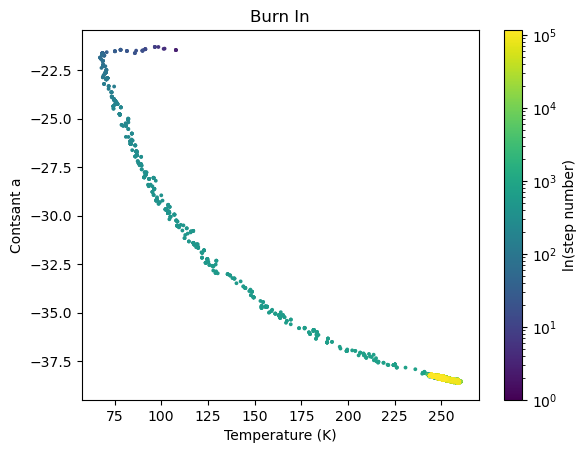

In [27]:
%matplotlib inline
from matplotlib.colors import LogNorm

jlist = np.arange(len(thetachain)) + 1
plt.scatter(thetachain[:,0],thetachain[:,1], c=jlist, norm=LogNorm(), cmap='viridis', s=3)
plt.colorbar(label='ln(step number)')
plt.title('Burn In')
plt.xlabel('Temperature (K)')
plt.ylabel('Contsant a')
plt.show()

In [7]:
np.max(loglikechain)

-2.3699492076035344

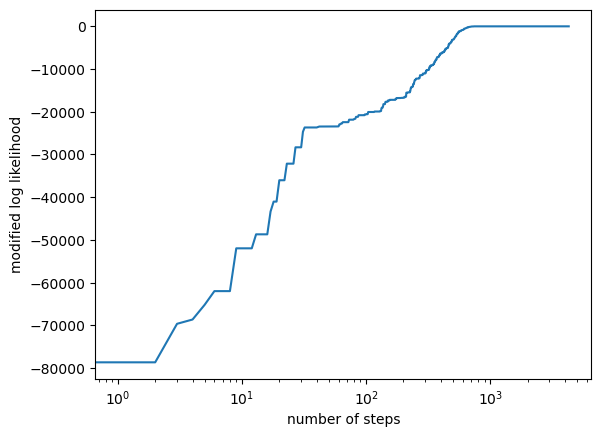

In [8]:
%matplotlib inline

plt.plot(loglikechain)
plt.xscale('log')
plt.ylabel('modified log likelihood')
plt.xlabel('number of steps')
plt.show()

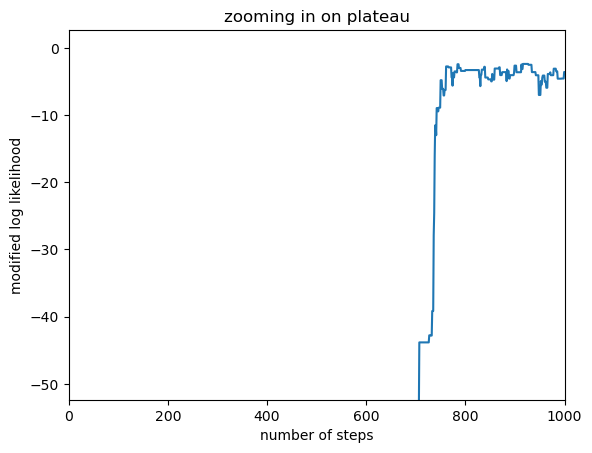

In [16]:
%matplotlib inline

plt.plot(loglikechain)
plt.ylim(np.max(loglikechain) - 50, np.max(loglikechain) + 5)
plt.xlim(0,1000)
plt.title('zooming in on plateau')
plt.ylabel('modified log likelihood')
plt.xlabel('number of steps')
plt.show()

In [17]:
def find_burnin(loglikechain):
    # reference level: median log-likelihood of the second half of the chain
    ref = np.median(loglikechain[len(loglikechain) // 2:])
    # first step at which the chain reaches that level
    return int(np.argmax(loglikechain >= ref))

burn-in ends at step 761


Text(0, 0.5, 'temperatyre ')

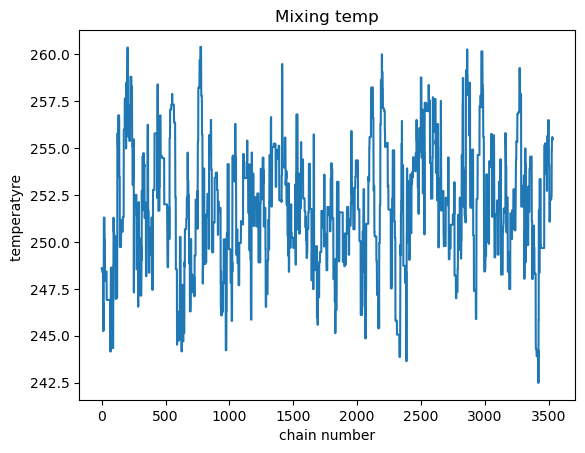

In [18]:
%matplotlib inline
# temperature mixing
burnj = find_burnin(loglikechain)
print(f"burn-in ends at step {burnj}")
plt.plot(thetachain[burnj:,0])
plt.title('Mixing temp')
plt.xlabel('chain number')
plt.ylabel('temperatyre ')

burn-in ends at step 761


Text(0, 0.5, 'temperatyre ')

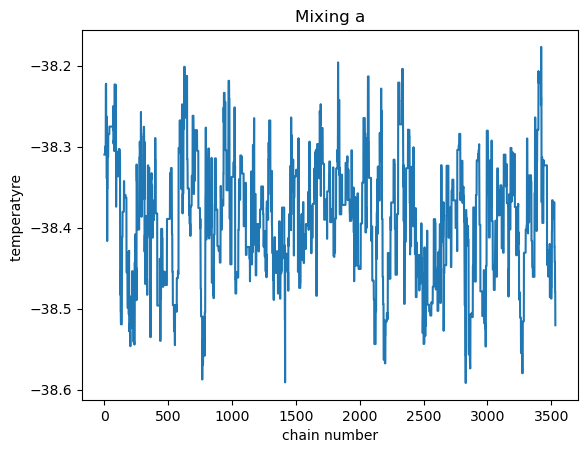

In [20]:
%matplotlib inline
# a constant mixing
burnj = find_burnin(loglikechain)
print(f"burn-in ends at step {burnj}")
plt.plot(thetachain[burnj:,1])
plt.title('Mixing a')
plt.xlabel('chain number')
plt.ylabel('temperatyre ')

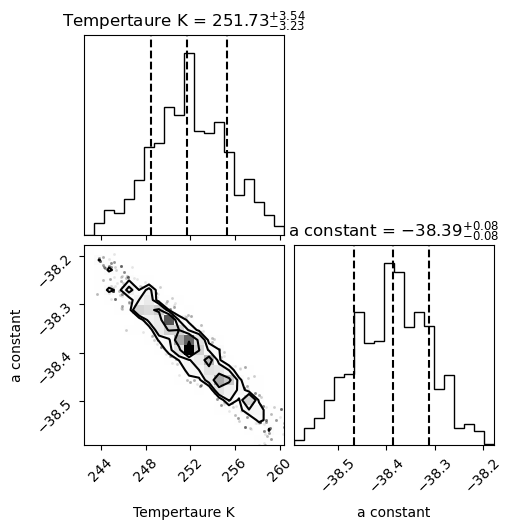

In [21]:
import corner

samples = thetachain[burnj:]
fig = corner.corner(
    samples,
    labels=['Tempertaure K','a constant'],
    quantiles=[0.16, 0.5, 0.84],     
    show_titles=True
)
plt.show()

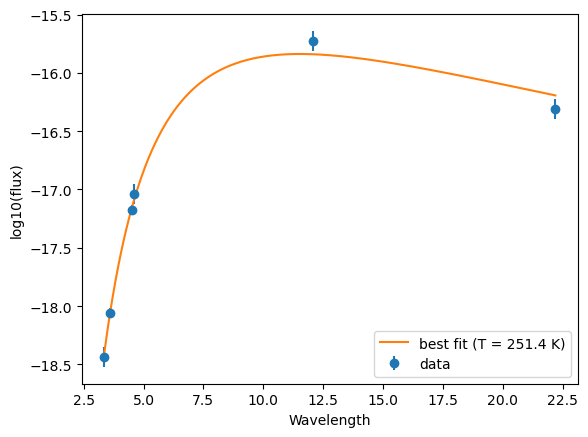

In [22]:
%matplotlib inline

T_best, a_best = thetachain[burnj:][np.argmax(loglikechain[burnj:])]

lam_grid = np.linspace(lam.min(), lam.max(), 500)

plt.errorbar(lam, logf, yerr=logf_err, fmt='o', label='data')
plt.plot(lam_grid, blackbody_model(lam_grid, T_best, a_best), label=f'best fit (T = {T_best:.1f} K)')
plt.xlabel('Wavelength')
plt.ylabel('log10(flux)')
plt.legend()
plt.show()

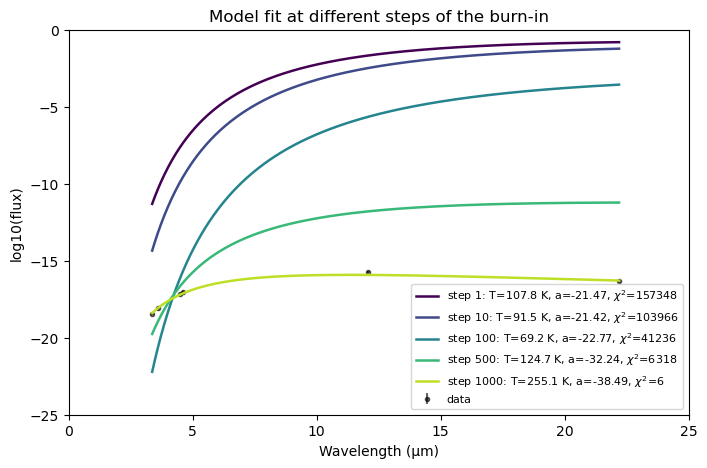

In [23]:
%matplotlib inline

steps = [1, 10, 100, 500, 1000]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(steps)))

lam_grid = np.linspace(lam.min(), lam.max(), 500)

plt.figure(figsize=(8, 5))
plt.errorbar(lam, logf, yerr=logf_err, fmt='o', color='k', ms=3, alpha=0.6,
             label='data', zorder=1)

for step, col in zip(steps, colors):
    T_s, a_s = thetachain[step]
    chi2_s = chi2(lam, logf, logf_err, thetachain[step])
    plt.plot(lam_grid, blackbody_model(lam_grid, T_s, a_s), color=col, lw=1.8,
             label=f'step {step}: T={T_s:.1f} K, a={a_s:.2f}, $\\chi^2$={chi2_s:.0f}',
             zorder=2)

# keep the y-range sensible, since early steps can be far from the data
plt.ylim(logf.min() - 1, logf.max() + 1)
plt.xlim(0,25)
plt.ylim(-25,0)
plt.xlabel('Wavelength (µm)')
plt.ylabel('log10(flux)')
plt.title('Model fit at different steps of the burn-in')
plt.legend(fontsize=8)
plt.show()